# Module 2 · Notebook 1: Attention from scratch

**Question for this notebook:** what does attention actually compute, and how do we prove our implementation is correct?

Everything is built on the autograd engine from Module 1 (`01-autograd/autograd.py`).

| Step | What we do |
|---|---|
| 1 | The idea: queries, keys, values |
| 2 | Single-head attention in plain NumPy, small enough to read every number |
| 3 | The causal mask: a language model must not see the future |
| 4 | The same thing on the autograd engine, plus a gradient check |
| 5 | Proof: changing a future token never changes earlier outputs |
| 6 | Multi-head attention, checked against a slow per-head loop |
| 7 | A first look at the $\sqrt{d}$ in the formula (the experiment is notebook 3) |

In [11]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# the Module 1 engine: notebooks/ -> 02-attention/ -> llm-lab/ -> 01-autograd/
LAB = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(LAB / "01-autograd"))
from autograd import Tensor, softmax
from gradcheck import gradcheck, TOL

print("python", sys.version.split()[0], "| numpy", np.__version__)
print("engine loaded from:", (LAB / "01-autograd").relative_to(LAB))

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

python 3.12.15 | numpy 2.5.3
engine loaded from: 01-autograd


## Step 1: The idea

A sentence comes in as $T$ vectors, one per token, each of size $C$. Attention lets every token **look at the other tokens and pull in information from the ones that matter to it**.

Each token produces three vectors from its own embedding, using three learned matrices:

| Vector | Question it answers |
|---|---|
| **query** $q = xW_q$ | "what am I looking for?" |
| **key** $k = xW_k$ | "what do I contain?" |
| **value** $v = xW_v$ | "what do I hand over if someone picks me?" |

Then, for every token:
1. **Score** every other token: $q \cdot k$ (a large dot product = a good match).
2. **Softmax** the scores into weights that are positive and sum to 1.
3. **Output** = the weighted average of the values.

All tokens at once, as matrices:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right) V$$

where $d$ is the size of each query/key vector. Step 7 and notebook 3 are about the $\sqrt{d}$; for now, read it as "a scaling factor".

It is a **soft dictionary lookup**: a normal dictionary returns the one value whose key matches exactly; attention returns a blend of all values, weighted by how well each key matches.

## Step 2: Single-head attention in plain NumPy

$T = 4$ tokens, $C = 3$ dimensions, so every number fits on screen.

In [12]:
rng = np.random.default_rng(0)
T, C = 4, 3
x = rng.standard_normal((T, C))           # 4 tokens, 3 numbers each
Wq, Wk, Wv = (rng.standard_normal((C, C)) / np.sqrt(C) for _ in range(3))   # usual init scale

Q, K, V = x @ Wq, x @ Wk, x @ Wv          # each (T, C)
scores = Q @ K.T / np.sqrt(C)             # (T, T): row i = how much token i likes each token j

def softmax_np(z):
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

weights = softmax_np(scores)               # (T, T), each row sums to 1
out = weights @ V                          # (T, C): one blended vector per token

np.set_printoptions(precision=3, suppress=True)
print("scores (row = query token, column = key token):\n", scores)
print("\nweights:\n", weights)
print("\nrow sums:", weights.sum(axis=1))
print("output shape:", out.shape)

scores (row = query token, column = key token):
 [[-0.071 -0.067 -0.004  0.073]
 [-0.08  -0.075  0.132 -0.038]
 [ 0.43   0.423 -2.263  1.565]
 [-0.306 -0.304  1.966 -1.425]]

weights:
 [[0.237 0.237 0.253 0.273]
 [0.234 0.235 0.289 0.243]
 [0.193 0.192 0.013 0.601]
 [0.083 0.083 0.806 0.027]]

row sums: [1. 1. 1. 1.]
output shape: (4, 3)


Read row 0 of `weights`: it says how token 0 splits its attention across tokens 0–3. The output for token 0 is exactly that mix of the 4 value vectors.

## Step 3: The causal mask

A language model predicts the **next** token. When it is computing position 2, tokens 3 and onward are the answer it is supposed to predict; if it can look at them, it learns to copy instead of predict.

So token $i$ may only attend to tokens $0 \dots i$. We enforce that by setting the forbidden scores to $-\infty$ **before** the softmax:
- $e^{-\infty} = 0$, so those weights become exactly 0;
- the remaining weights in each row still sum to 1.

The mask is a constant matrix: 0 on and below the diagonal, $-\infty$ above it.

In [13]:
mask = np.triu(np.full((T, T), -np.inf), k=1)    # -inf strictly above the diagonal
print("mask:\n", mask)

weights_causal = softmax_np(scores + mask)
print("\ncausal weights:\n", weights_causal)
print("\nrow sums:", weights_causal.sum(axis=1))

mask:
 [[  0. -inf -inf -inf]
 [  0.   0. -inf -inf]
 [  0.   0.   0. -inf]
 [  0.   0.   0.   0.]]

causal weights:
 [[1.    0.    0.    0.   ]
 [0.499 0.501 0.    0.   ]
 [0.485 0.482 0.033 0.   ]
 [0.083 0.083 0.806 0.027]]

row sums: [1. 1. 1. 1.]


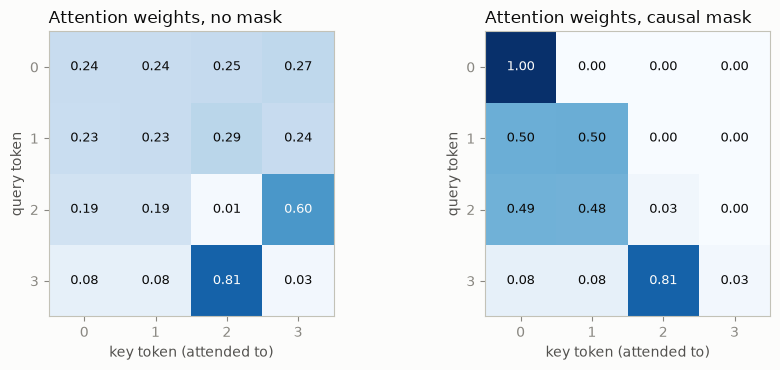

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, w, title in [(axes[0], weights, "no mask"), (axes[1], weights_causal, "causal mask")]:
    ax.imshow(w, cmap="Blues", vmin=0, vmax=1)
    for i in range(T):
        for j in range(T):
            ax.text(j, i, f"{w[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color=SURFACE if w[i, j] > 0.55 else INK)
    ax.set_xticks(range(T)); ax.set_yticks(range(T))
    ax.set_xlabel("key token (attended to)"); ax.set_ylabel("query token")
    ax.set_title(f"Attention weights, {title}", loc="left")
plt.tight_layout()
plt.show()

With the mask, the upper triangle is exactly 0: token 0 can only look at itself, token 3 can look at everything before it.

## Step 4: The same thing on the autograd engine

Now with `Tensor` from Module 1, so we get gradients for free. Two details:

- **Transposing $K$.** The engine's `transpose` takes the full axis order. For a batch of shape `(B, T, d)` we need to swap only the last two axes, so a small helper builds that order.
- **The mask needs no new op.** It is just `scores + mask`, where `mask` is a constant array. In the backward pass, the gradient flowing into a masked score goes through `exp`, whose local derivative is $e^{-\infty} = 0$. So masked positions get **exactly zero gradient**, with the ops we already have.

In [15]:
def swap_last2(t):
    n = t.data.ndim
    return t.transpose(tuple(range(n - 2)) + (n - 1, n - 2))

def causal_mask(T):
    return np.triu(np.full((T, T), -np.inf), k=1)

def attention(q, k, v, causal=True):
    # q, k, v: Tensors of shape (..., T, d)
    T, d = q.shape[-2], q.shape[-1]
    scores = (q @ swap_last2(k)) * (1.0 / np.sqrt(d))
    if causal:
        scores = scores + causal_mask(T)
    return softmax(scores, axis=-1) @ v

# same numbers as Step 3: the engine must reproduce the plain NumPy result
out_engine = attention(Tensor(Q), Tensor(K), Tensor(V)).data
out_numpy = weights_causal @ V
print("max |engine - numpy| =", np.abs(out_engine - out_numpy).max())

max |engine - numpy| = 2.7755575615628914e-17


**Gradient check.** Batch of 2 sequences, $T = 5$, $d = 4$, with the mask on. The checker from Module 1 (float64, central differences) compares every gradient against finite differences.

In [16]:
B, T, d = 2, 5, 4
q0, k0, v0 = (rng.standard_normal((B, T, d)) for _ in range(3))

err = gradcheck(lambda t: attention(t[0], t[1], t[2], causal=True), [q0, k0, v0])
print(f"attention (causal) gradcheck: rel_err = {err:.1e}   {'OK' if err < TOL else 'FAIL'}")

err = gradcheck(lambda t: attention(t[0], t[1], t[2], causal=False), [q0, k0, v0])
print(f"attention (no mask) gradcheck: rel_err = {err:.1e}   {'OK' if err < TOL else 'FAIL'}")

# masked positions really get zero gradient: q at position 0 only sees k at position 0,
# so the gradient of output[0] w.r.t. k at positions 1..4 must be exactly 0
q, k, v = Tensor(q0), Tensor(k0), Tensor(v0)
out = attention(q, k, v)
(out * np.eye(T)[0][None, :, None]).sum().backward()      # loss = sum of output at position 0 only
print("grad of k at positions 1..4 from output[0]:", np.abs(k.grad[:, 1:]).max())

attention (causal) gradcheck: rel_err = 2.9e-10   OK
attention (no mask) gradcheck: rel_err = 3.6e-10   OK
grad of k at positions 1..4 from output[0]: 0.0


## Step 5: Proof that the mask works

A gradient check proves the derivatives are right. It does **not** prove the model can't see the future. That needs its own test:

> Change the token at position $t$. Outputs at positions **before** $t$ must not change at all. Outputs at $t$ and after should change.

And the same test without the mask, to show what a leak looks like.

In [17]:
T, C = 6, 8
x = rng.standard_normal((T, C))
Wq, Wk, Wv = (rng.standard_normal((C, C)) / np.sqrt(C) for _ in range(3))

def single_head(x, causal):
    X = Tensor(x)
    return attention(X @ Tensor(Wq), X @ Tensor(Wk), X @ Tensor(Wv), causal=causal).data

t_changed = 3
x2 = x.copy()
x2[t_changed] += rng.standard_normal(C)      # change token 3 only

for causal in [True, False]:
    diff = np.abs(single_head(x, causal) - single_head(x2, causal)).max(axis=1)
    print(f"causal={causal}:")
    for pos in range(T):
        tag = "before the change" if pos < t_changed else "at/after the change"
        print(f"   position {pos}: max change = {diff[pos]:.2e}   ({tag})")

causal=True:
   position 0: max change = 0.00e+00   (before the change)
   position 1: max change = 0.00e+00   (before the change)
   position 2: max change = 0.00e+00   (before the change)
   position 3: max change = 1.22e+00   (at/after the change)
   position 4: max change = 1.56e+00   (at/after the change)
   position 5: max change = 7.59e-02   (at/after the change)
causal=False:
   position 0: max change = 2.73e-02   (before the change)
   position 1: max change = 1.04e-01   (before the change)
   position 2: max change = 3.29e-02   (before the change)
   position 3: max change = 9.27e-01   (at/after the change)
   position 4: max change = 1.23e+00   (at/after the change)
   position 5: max change = 7.59e-02   (at/after the change)


With the mask, positions 0–2 change by **exactly 0.0**, not "almost 0": their weights on token 3 are exactly $e^{-\infty} = 0$. Without the mask, every position changes: token 0 is reading the future.

## Step 6: Multi-head attention

One attention head can only compute one kind of "match". Real models run $H$ heads in parallel, each on its own slice of the vector:

1. Compute $Q, K, V$ for all heads at once: `(B, T, C)`.
2. **Split** the last dimension into $H$ heads of size $C/H$: reshape to `(B, T, H, C/H)`, then move heads forward: `(B, H, T, C/H)`.
3. Run attention. The batched matmul from Module 1 treats `(B, H)` as batch dimensions, so all heads run in one call.
4. **Merge**: move heads back and reshape to `(B, T, C)`.
5. A final output projection $W_o$ mixes the heads.

There is no loop over heads: it is all reshapes and transposes, which is also how real implementations do it.

In [18]:
def split_heads(x, H):                       # (B, T, C) -> (B, H, T, C/H)
    B, T, C = x.shape
    return x.reshape(B, T, H, C // H).transpose((0, 2, 1, 3))

def merge_heads(x):                          # (B, H, T, hs) -> (B, T, H*hs)
    B, H, T, hs = x.shape
    return x.transpose((0, 2, 1, 3)).reshape(B, T, H * hs)

def multi_head_attention(x, Wq, Wk, Wv, Wo, H, causal=True):
    q, k, v = split_heads(x @ Wq, H), split_heads(x @ Wk, H), split_heads(x @ Wv, H)
    return merge_heads(attention(q, k, v, causal)) @ Wo


def multi_head_slow(x, Wq, Wk, Wv, Wo, H):
    # reference: plain NumPy, explicit loops over batch and heads, no reshapes
    B, T, C = x.shape
    hs = C // H
    out = np.zeros((B, T, C))
    for b in range(B):
        Q, K, V = x[b] @ Wq, x[b] @ Wk, x[b] @ Wv
        heads = []
        for h in range(H):
            cols = slice(h * hs, (h + 1) * hs)
            w = softmax_np(Q[:, cols] @ K[:, cols].T / np.sqrt(hs) + causal_mask(T))
            heads.append(w @ V[:, cols])
        out[b] = np.concatenate(heads, axis=1) @ Wo
    return out

B, T, C, H = 2, 6, 16, 4
x = rng.standard_normal((B, T, C))
W = [rng.standard_normal((C, C)) * 0.3 for _ in range(4)]

fast = multi_head_attention(Tensor(x), *[Tensor(w) for w in W], H=H).data
slow = multi_head_slow(x, *W, H=H)
print(f"heads={H}, head size={C // H}")
print("max |fast - slow loop| =", np.abs(fast - slow).max())

heads=4, head size=4
max |fast - slow loop| = 4.440892098500626e-16


**Gradient check of the whole multi-head layer**, against all five inputs at once ($x$, $W_q$, $W_k$, $W_v$, $W_o$). This checks that split → attention → merge → projection is wired correctly end to end, including the reshapes and transposes.

In [19]:
B, T, C, H = 2, 4, 8, 2
inputs = [rng.standard_normal((B, T, C))] + [rng.standard_normal((C, C)) * 0.3 for _ in range(4)]
n_numbers = sum(a.size for a in inputs)

err = gradcheck(lambda t: multi_head_attention(t[0], t[1], t[2], t[3], t[4], H=H), inputs)
print(f"multi-head attention gradcheck ({n_numbers} numbers checked): rel_err = {err:.1e}   {'OK' if err < TOL else 'FAIL'}")

multi-head attention gradcheck (320 numbers checked): rel_err = 5.3e-10   OK


## Step 7: A first look at $\sqrt{d}$

Why divide the scores by $\sqrt{d}$? A quick measurement. Take random query and key vectors with unit-variance entries, and look at their dot product as the vector size $d$ grows:

In [20]:
T = 16
print(f"{'d':>5s} | {'std of q.k':>11s} {'avg max weight':>15s} | {'std of q.k/sqrt(d)':>19s} {'avg max weight':>15s}")
for d in [16, 64, 256, 1024]:
    q = rng.standard_normal((2000, d))
    k = rng.standard_normal((2000, T, d))
    raw = np.einsum("nd,ntd->nt", q, k)          # 2000 rows of T scores each
    scaled = raw / np.sqrt(d)
    print(f"{d:5d} | {raw.std():11.1f} {softmax_np(raw).max(axis=1).mean():15.3f} | "
          f"{scaled.std():19.2f} {softmax_np(scaled).max(axis=1).mean():15.3f}")

    d |  std of q.k  avg max weight |  std of q.k/sqrt(d)  avg max weight
   16 |         4.0           0.692 |                1.00           0.245
   64 |         7.9           0.840 |                0.99           0.243
  256 |        16.0           0.919 |                1.00           0.242
 1024 |        32.2           0.959 |                1.01           0.247


- **Without scaling**, the spread of the scores grows like $\sqrt{d}$ (a sum of $d$ random terms). At $d = 1024$ it is ~32, and softmax puts nearly all the weight on a single token: the "average max weight" approaches 1. That is softmax **saturation**.
- **With scaling**, the spread stays ~1 for every $d$, and the weights stay spread out.

Saturation is bad for more than the forward pass: when softmax is saturated, its gradient is close to 0, so the model can barely learn which tokens to attend to. **Notebook 3 measures exactly that**: attention entropy and gradient size as $d$ grows, with and without scaling.

## Summary

- **Attention = a soft dictionary lookup**: score with $q \cdot k$, softmax into weights, average the values.
- **The causal mask** is just a constant $-\infty$ added before softmax. No new engine op; masked positions get exactly 0 weight and exactly 0 gradient.
- **Proof, three ways:** gradient check (derivatives), the "change a future token" test (no leak), and multi-head against a slow loop (reshapes are right).
- **Multi-head** is reshapes and transposes around one batched attention call.

## Next: Notebook 2, the transformer block

LayerNorm, residual connections, the MLP, and three ways to tell the model where each token is (sinusoidal, learned, RoPE).